# Credit risk: probability of default, expected loss and FICO ratings

Three questions on a book of 10,000 loans (18.5% defaulted): **(1)** how predictable is default, **(2)** what is the expected loss on a new borrower, **(3)** how should FICO scores be mapped to a small number of ratings?

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import numpy as np, pandas as pd
from quant_research import *
from quant_research import viz
pd.set_option('display.width', 120)
loans = load_loans()
loans.describe().T[['min','50%','max']]

,min,50%,max
customer_id,1.000324e+06,4.989502e+06,8.999789e+06
credit_lines_outstanding,0.000000e+00,1.000000e+00,5.000000e+00
loan_amt_outstanding,4.678397e+01,4.052377e+03,1.075068e+04
total_debt_outstanding,3.165273e+01,6.732407e+03,4.368878e+04
income,1.000000e+03,7.008583e+04,1.484122e+05
years_employed,0.000000e+00,5.000000e+00,1.000000e+01
fico_score,4.080000e+02,6.380000e+02,8.500000e+02
default,0.000000e+00,0.000000e+00,1.000000e+00
debt_to_income,1.000000e-02,9.743396e-02,4.045607e-01


## 1. How predictable is default?

Before fitting anything, check how much a *single* feature explains.

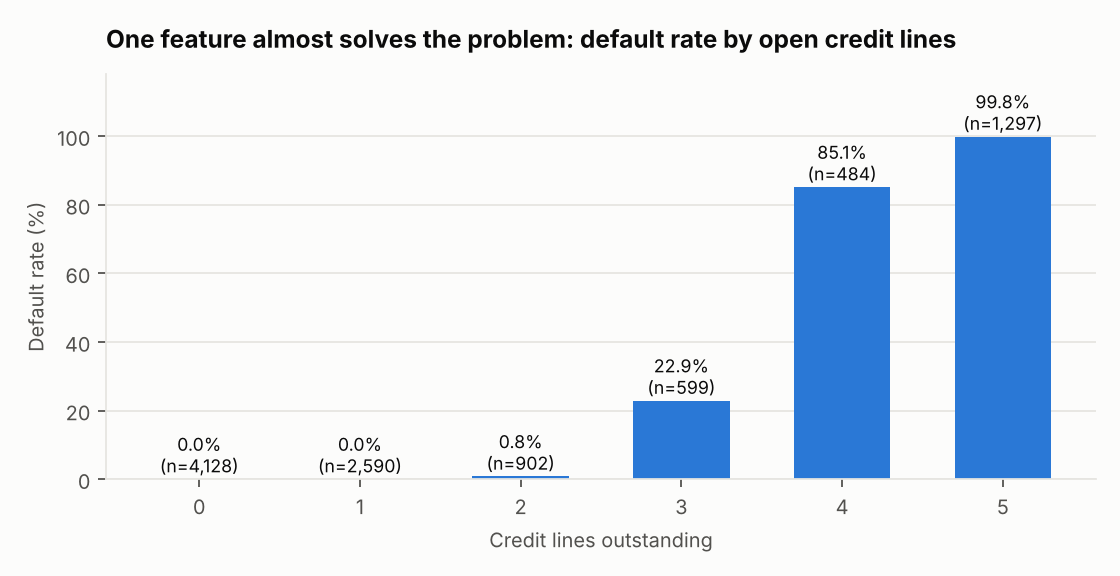

In [2]:
viz.default_rate_by_credit_lines(loans, '../docs/default_by_credit_lines.png')
from IPython.display import Image; Image('../docs/default_by_credit_lines.png')

Nobody with 0-1 open credit lines defaulted and almost everyone with 5 did. So this data set is **near-deterministic**: ROC-AUC near 1.0 comes from the data, not from a clever model. The table puts that next to the models, with a single-feature baseline.

In [3]:
results = evaluate_models(loans)
results

,model,test_auc,test_brier,cv_auc_mean
0,single feature: credit_lines_outstanding,0.99509,0.05190,NaN
1,single feature: fico_score,0.71352,0.20691,NaN
2,logistic,0.99999,0.00285,0.99998
3,gradient_boosting,0.99989,0.00398,0.99992


Reading it honestly: the single feature `credit_lines_outstanding` already reaches AUC 0.995; logistic regression adds the last half-point. FICO alone is weak here (0.71). A real lending book would not look like this, so treat the near-perfect scores as a property of the exercise data.

## 2. Expected loss

`EL = PD x (1 - recovery) x loan balance`, with a 10% recovery rate. The function **warns when an input is outside the training range**, because the earlier version of this analysis reported a 98.8% PD for a borrower whose debt-to-income (0.6) was above anything in the data (max 0.41).

In [4]:
model = fit_default_model(loans)
typical = dict(credit_lines_outstanding=2, loan_amt_outstanding=7000, total_debt_outstanding=15000,
               income=50000, years_employed=4, fico_score=610)
p, el = expected_loss(model, typical)
print(f'PD {p:.1%}   expected loss ${el:,.0f}')
outlier = dict(typical, total_debt_outstanding=30000, loan_amt_outstanding=10000, fico_score=700, years_employed=10)
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    p2, el2 = expected_loss(model, outlier)
print(f'PD {p2:.1%}  <- {w[0].message}')

PD 87.0%   expected loss $5,483
PD 100.0%  <- inputs outside training range, PD is an extrapolation: ['debt_to_income']


## 3. FICO to rating by dynamic programming

Choose bucket boundaries that maximise the log-likelihood of the observed defaults, `sum_b k_b ln(p_b) + (n_b - k_b) ln(1 - p_b)`. An exact DP over the ~440 distinct scores finds the global optimum (tested against brute force). Equal-frequency `qcut` bins, the usual shortcut, ignore defaults.

In [5]:
from quant_research.fico_buckets import _bucket_loglik
rows=[]
for k in (3,5,8):
    e,ll=optimal_fico_buckets(loans.fico_score, loans.default, k)
    q=pd.qcut(loans.fico_score,k,labels=False)
    qll=sum(_bucket_loglik(np.array([(q==i).sum()]),np.array([loans.default[q==i].sum()]))[0] for i in range(k))
    rows.append(dict(buckets=k, dp_loglik=round(ll,1), qcut_loglik=round(qll,1), gain=round(ll-qll,1), dp_edges=e))
pd.DataFrame(rows)

,buckets,dp_loglik,qcut_loglik,gain,dp_edges
0,3,-4319.5,-4371.8,52.3,"[579.0, 649.0]"
1,5,-4255.4,-4321.0,65.7,"[520.0, 580.0, 640.0, 696.0]"
2,8,-4224.3,-4280.2,55.9,"[520.0, 552.0, 580.0, 611.0, 649.0, 696.0, 732.0]"


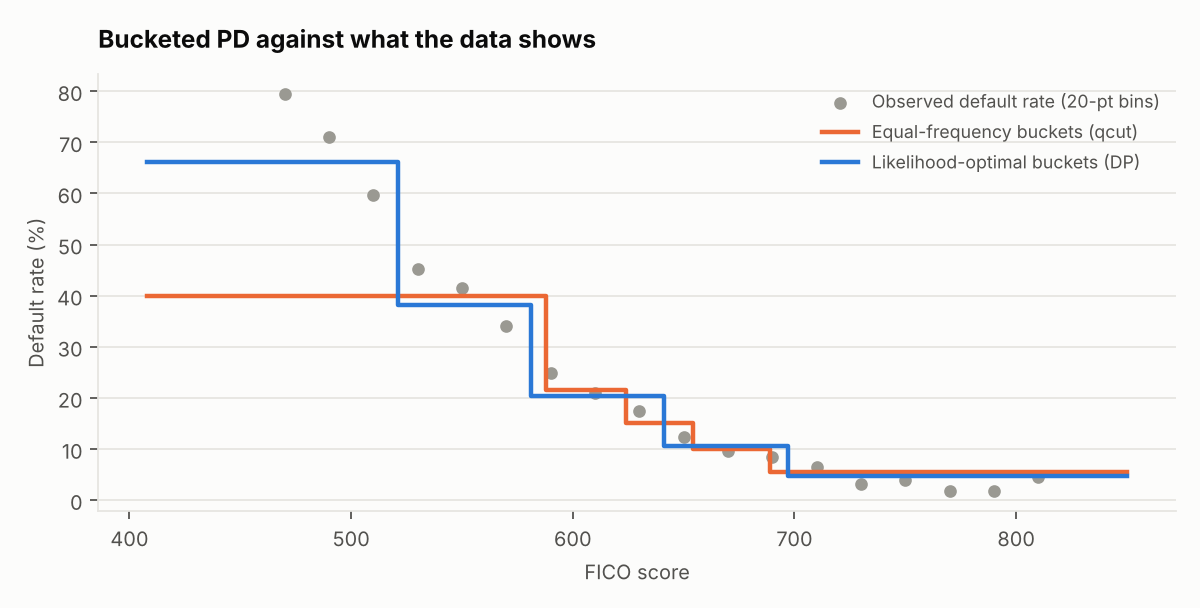

In [6]:
dp_edges,_ = optimal_fico_buckets(loans.fico_score, loans.default, 5)
q_edges = pd.qcut(loans.fico_score, 5, retbins=True)[1][1:-1].tolist()
viz.bucket_pd_curves(loans, dp_edges, q_edges, '../docs/fico_buckets.png')
Image('../docs/fico_buckets.png')

In [7]:
loans['rating'] = assign_rating(loans.fico_score, dp_edges)   # 1 = best credit
loans.groupby('rating').agg(borrowers=('default','size'), default_rate=('default','mean'),
                            fico_min=('fico_score','min'), fico_max=('fico_score','max')).round(3)

,borrowers,default_rate,fico_min,fico_max
rating,,,,
1,1657,0.046,697,850
2,3197,0.105,641,696
3,3438,0.204,581,640
4,1407,0.381,521,580
5,301,0.661,408,520


Ratings are monotone (rating 1 = best): default rate rises as the rating worsens, and the DP boundaries sit where default behaviour actually changes.